# Interpretability Analysis (ANN saliency)

**Purpose:** Explain what the 24-PC ANN classifiers use to decide (manuscript Sections 3.3-3.5 and 4.3). Gradient-based saliency is computed for each fold's selected ANN, back-projected from principal components to wavenumbers through that fold's PCA loadings, and thresholded to find the most influential spectral regions.

**Input:**
- `Performance Dictionaries/Performance_ANN_PCA_nCV.pkl` (24-PC models and fitted PCA objects, from `ANN_PCA_HypTune.ipynb`)
- `Preprocessed_Raman_Spectra_2025.pkl` (wavenumber axis)

**Pipeline per classifier and outer fold:**
1. **Transfer the model to PyTorch.** The fitted scikit-learn `MLPClassifier` (hidden sizes, activation, output activation, weights, biases) is rebuilt as an equivalent `torch.nn.Sequential` so gradients can be taken with Captum (`model_interp`).
2. **Saliency (Eq. 1).** Captum `Saliency` gives |d output / d input| for every training spectrum; scores are averaged over the training spectra and L2-normalised, giving one score per PC (0-1).
3. **Back-projection (Eq. 2).** Saliency x |PCA loading| summed over the 24 PCs gives an importance per wavenumber, comparable across folds because all folds share the same wavenumber axis.
4. **Thresholding (Section 3.5).** Wavenumbers with z-score >= 2.5 are flagged; regions flagged in at least two of the three folds are kept as consistently influential.

**Classifiers:** species (single output), benzoate condition (`metabolites`, single output) and culture age (three outputs, so saliency is computed per class: target 0 = 5 h, 1 = 24 h, 2 = 48 h).

**Output figures:** `Figure_6.jpg` (species), `Figure_7.jpg` (benzoate), `Figure_S2-S4.jpg` (age 5 / 24 / 48 h) and `Figure_8.svg` (Venn diagram of the age-class regions), all in `Paper and SI images/`.

**Order of execution:** later cells re-use `cmap` and `norm` that are first defined in the species figure cell, so run the notebook top to bottom.

In [1]:
# Imports. torch + captum (Saliency) are used for the interpretability; the rest is plotting and scikit-learn typing.
# IntegratedGradients and Occlusion are imported but not used.
import math
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'
from pathlib import Path

# pytorch relates imports

import torch
import torch.nn as nn
import torch.optim as optim

# imports from captum library
from captum.attr import IntegratedGradients, Saliency, Occlusion

import pandas as pd
pd.DataFrame.iteritems = pd.DataFrame.items

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits import mplot3d
import matplotlib.ticker as mticker
import matplotlib.transforms as transforms
import matplotlib.patches as patches
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import scipy
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA, KernelPCA
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.neural_network import MLPClassifier
from sklearn import metrics
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Load the nested-CV ANN results with PCA inputs and the preprocessed dataset (for the wavenumber axis)
ann_pca_filename = "Performance Dictionaries\\Performance_ANN_PCA_nCV.pkl"

with open(ann_pca_filename, "rb") as file:
    ANN_pca_loaded_performance = pickle.load(file)
print(ANN_pca_loaded_performance.keys())

datasetname = "Preprocessed_Raman_Spectra_2025.pkl"

with open(datasetname, "rb") as file:
    loaded_data = pickle.load(file)
print(loaded_data.keys())

dict_keys(['CV 1', 'CV 2', 'CV 3'])
dict_keys(['Spectra', 'wavenumber', 'species label', 'culture age', 'culture condition', 'biological replicate', 'technical replicate', 'Preprocess conditions'])


species
Mean average: 0.91
Std average: 0.01
~~~~~~~~~~~~~~~~~~~~~
metabolites
Mean average: 0.83
Std average: 0.01
~~~~~~~~~~~~~~~~~~~~~
age
Mean average: 0.84
Std average: 0.04
~~~~~~~~~~~~~~~~~~~~~


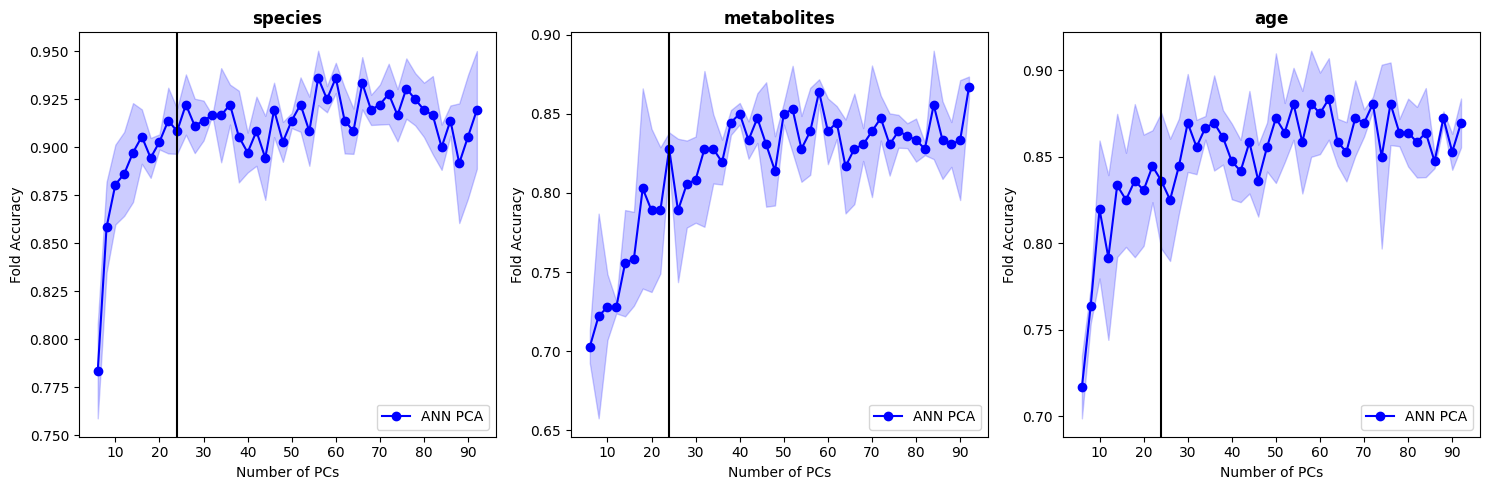

In [3]:
# Accuracy vs number of PCs for the ANN (mean +/- SD over the 3 outer folds) for each task.
# The vertical line marks 24 PCs, the number used for all three classifiers; the printed mean/SD at 24 PCs are the accuracies reported in the abstract.
fig, axs = plt.subplots(1, 3, figsize = (15, 5), sharex = True)
ax = axs.ravel()

folds = list(ANN_pca_loaded_performance.keys())
pcs = np.array(list(ANN_pca_loaded_performance[folds[0]][0].keys()))
names = list(ANN_pca_loaded_performance[folds[0]][0][pcs[0]].keys())

average_accuracy = []

for i in range(len(names)):
    acc_a_overall = []

    for n in pcs:
        temp_a_acc = []

        for f in folds:
            temp_a_acc.append(ANN_pca_loaded_performance[f][0][n][names[i]][-1]["accuracy"])
        acc_a_overall.append(temp_a_acc)

    acc_a_m = np.mean(np.array(acc_a_overall), axis = 1)
    acc_a_s = np.std(np.array(acc_a_overall), axis = 1)
    
    ind_24 = np.argmax(pcs == 24)
    print(names[i])
    print("Mean average:", round(acc_a_m[ind_24],2))
    print("Std average:", round(acc_a_s[ind_24], 2))
    print("~~~~~~~~~~~~~~~~~~~~~")
    
    average_accuracy.append(acc_a_m)
    ax[i].plot(pcs, acc_a_m, "-o", label = "ANN PCA", color = "blue")
    ax[i].fill_between(pcs, acc_a_m - acc_a_s, acc_a_m + acc_a_s, alpha = 0.2, color = "blue")
    ax[i].set_xlabel("Number of PCs")
    ax[i].set_ylabel("Fold Accuracy")
    ax[i].set_title(names[i], fontweight = "bold")
    ax[i].legend(loc = "lower right")
    ax[i].xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax[i].axvline(x = 24, color = "k")

plt.tight_layout()

# ANN - 24 PCA Interpretability

In [4]:
# Convert one fold's fitted scikit-learn MLPClassifier into an equivalent PyTorch network and return its normalised saliency per input PC.
#   model_list : result list for one fold / task: [X_train, y_train, X_test, y_test, y_predict, GridSearchCV, best model, confusion matrix, report]
#   target     : output class for which to compute saliency; None for the single-output binary classifiers, 0/1/2 for the 3-class age model
# Returns a vector of length 24 (one value per PC) with unit L2 norm (manuscript Eq. 1 and the averaging/normalisation described in Section 3.3).
def model_interp(model_list, target = None):
    
    # Fitted scikit-learn model for this fold / task
    model = model_list[6]

    # Training inputs: the first 24 PC scores of the training spectra of this fold
    X_train = model_list[0]
    # (confusion matrix, not used below)
    con_mat = model_list[-2]
    
    # Read the sklearn architecture: hidden layer sizes, hidden activation, output activation, number of outputs, weights and biases
    model_arch = model.hidden_layer_sizes
    model_act = model.activation
    
    model_out_act = model.out_activation_
    model_num_out = model.n_outputs_
    
    model_weight = model.coefs_
    model_intercepts = model.intercepts_

    #print(model_arch, model_act, model_out_act, model_num_out)
    
    # Rebuild the network in PyTorch: Linear layer + activation for each hidden layer ...
    layers = []

    layers.append(nn.Linear(model.n_features_in_, model_arch[0]))
    if model_act == "logistic":
        layers.append(nn.Sigmoid())
    elif model_act == "tanh":
        layers.append(nn.Tanh())
    elif model_act == "relu":
        layers.append(nn.ReLU())

    for i in range(len(model_arch)-1):
        layers.append(nn.Linear(model_arch[i], model_arch[i+1]))
        if model_act == "logistic":
            layers.append(nn.Sigmoid())
        elif model_act == "tanh":
            layers.append(nn.Tanh())
        elif model_act == "relu":
            layers.append(nn.ReLU())

    # ... and the output layer: 1 output with logistic (sigmoid) for the binary tasks, 3 outputs with softmax for the age task
    layers.append(nn.Linear(model_arch[-1], model_num_out))
    if model_out_act == "logistic":
        layers.append(nn.Sigmoid())
    elif model_out_act == "softmax":
        layers.append(nn.Softmax())

    pyt_model = nn.Sequential(*layers)
    
#     print(pyt_model)
#     print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

    # Copy the trained weights: sklearn stores coefs_[i] as (inputs x outputs), PyTorch wants (outputs x inputs), hence the transpose.
    # Linear layers sit at even positions of the Sequential (activations are in between).
    with torch.no_grad():
        for i in range(len(model_arch)+1):
            k = 2*i
            pyt_model[k].weight.copy_(torch.from_numpy(model_weight[i].T))
            pyt_model[k].bias.copy_(torch.from_numpy(model_intercepts[i].T))
    
    # Captum Saliency = absolute gradient of the selected output with respect to each input (the absolute value discards the sign, Eq. 1)
    Sal = Saliency(pyt_model)
    X_trn = torch.tensor(X_train, dtype = torch.float32)
    
    # Gradient for the chosen output class (age model) or for the single output (binary models)
    if target != None:
        attr = Sal.attribute(X_trn, target)
    else:
        attr = Sal.attribute(X_trn)
    
    # Average over all training spectra, then L2-normalise so scores lie between 0 and 1 and can be compared across folds
    sal = attr.detach().numpy()
    
    sal_mean = np.mean(sal, axis = 0)
    sal_norm = sal_mean/np.linalg.norm(sal_mean)
    
    return sal_norm

# Species Model Interpretability

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
CV 1 - fold selected model architecute
ANN Architecture (hidden):   (20,)
ANN activation:              logistic
ANN output activation:       logistic
ANN number of outputs:       1
Input features (n_features): 24
Total layers (incl. in/out): 3
Alpha (L2 penalty):          1e-05
Batch size:                  16
Solver:                      adam
Initial learning rate:       0.001
Learning rate schedule:      constant
Max iterations (allowed):    2000
Iterations run (n_iter_):    536
Final training loss:         0.007407489382381917
Random state:                42
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
CV 2 - fold selected model architecute
ANN Architecture (hidden):   (20,)
ANN activation:              logistic
ANN output activation:       logistic
ANN number of outputs:       1
Input features (n_features): 24
Total layers (incl. in/out): 3
Alpha 

C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\captum\_utils\gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\captum\_utils\gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\captum\_utils\gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(


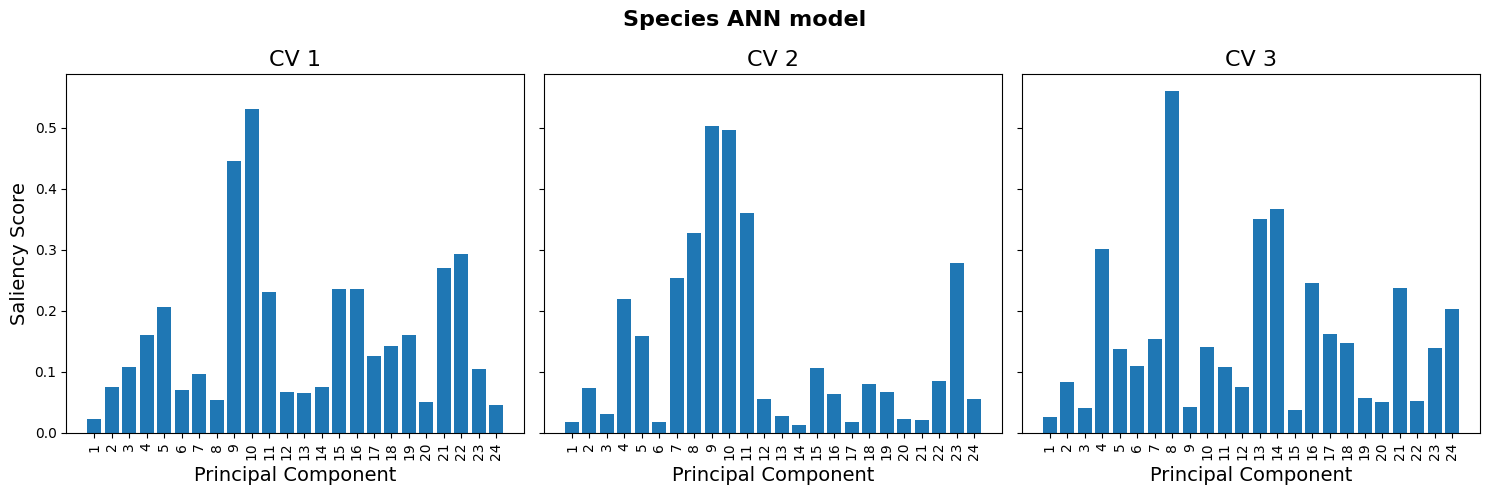

In [5]:
# Species model: for each outer fold, print the selected ANN's settings, compute the saliency of each of the 24 PCs and plot it.
# sal_thresh is defined but not used. species_interp_scores[fold] = [PCA loadings (components_), saliency vector] for the back-projection below.
fig, axs = plt.subplots(1, 3, figsize = (15, 5), sharex = True, sharey = True)
ax = axs.ravel()
i = 0
sal_thresh = 0.35

species_interp_scores = {}

for f in folds:
    model_list = ANN_pca_loaded_performance[f][0][24]["species"]
    
    # Print the selected ANN's configuration for this fold
    print("~~"*30)
    print(f +  " - fold selected model architecute")
    model = model_list[6]
    print("ANN Architecture (hidden):  ", model.hidden_layer_sizes)
    print("ANN activation:             ", model.activation)
    print("ANN output activation:      ", model.out_activation_)
    print("ANN number of outputs:      ", model.n_outputs_)

    # additional details
    print("Input features (n_features):", model.n_features_in_)
    print("Total layers (incl. in/out):", model.n_layers_)
    print("Alpha (L2 penalty):         ", model.alpha)
    print("Batch size:                 ", model.batch_size)
    print("Solver:                     ", model.solver)
    print("Initial learning rate:      ", model.learning_rate_init)
    print("Learning rate schedule:     ", model.learning_rate)   # only used if solver == 'sgd'
    print("Max iterations (allowed):   ", model.max_iter)
    print("Iterations run (n_iter_):   ", model.n_iter_)
    print("Final training loss:        ", model.loss_)
    print("Random state:               ", model.random_state)
    print("~~"*30)
    
    # Saliency per PC for this fold, then plot it
    sal_norm = model_interp(model_list)
    
    ax[i].bar(range(1, len(sal_norm)+1), sal_norm, capsize = 2)
    ax[i].set_xticks(range(1, len(sal_norm)+1))
    ax[i].set_xticklabels(labels = range(1, len(sal_norm)+1), rotation = 90, fontsize = 10)
    ax[i].tick_params(axis='y', labelsize=10)
    ax[i].set_xlabel("Principal Component", fontsize = 14)
    ax[i].set_title(f,fontsize = 16)
    if i ==0:
        ax[i].set_ylabel("Saliency Score", fontsize = 14)
    i += 1
    species_interp_scores[f] = [ANN_pca_loaded_performance[f][1].components_, sal_norm]
    

fig.suptitle("Species ANN model", fontsize = 16, fontweight = "bold")
plt.tight_layout()

In [6]:
# Helper for the left column of the saliency figures: stacked bar per PC. The bar of PC i is split into one coloured segment per wavenumber (cividis colour scale
# over wavenumber); the segment height is saliency_i x loading_ij^2. Since each PC's loadings have unit length the segments add up to saliency_i.
def plot_saliency_score(sal, pcw, ax, fig, wv):
    score_cum = []

    for i in range(len(pcw)):
        temp = sal[i]*(pcw[i,:]**2)#/np.sum(pcw[i,:])
        score_cum.append(temp)

    score_cum = np.array(score_cum)
    
    cmap = cm.get_cmap('cividis')
    norm = plt.Normalize(vmin=np.min(wv)-50, vmax=np.max(wv)+50)

    for i in range(np.shape(score_cum)[1]):
        #print(i)
        val = score_cum[:,i]
        if i == 0:
            bot = 0
        else:
            bot = np.sum(score_cum[:, :i], axis = 1)

        ax.bar(range(1, len(sal)+1), val, bottom = bot, color = cmap(norm(wv[i])))#, alpha = 0.85)

C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\A

[ 728.  729.  730.  731.  734.  735.  736.  865.  866.  870.  871.  872.
  873.  877.  878.  879.  880.  884.  885. 1213. 1777. 1778. 1779. 1780.
 1781. 1782. 1783. 1784. 1785.]
~~~~~~~~~~~~~~~~~~~~~
[ 485.  486.  487.  490.  491.  492.  496.  730.  731.  870.  871.  872.
  873.  877.  878.  879.  880.  884.  885.  886.  887.  888.  892.  893.
  956.  957.  958. 1008. 1009. 1013. 1014.]
~~~~~~~~~~~~~~~~~~~~~
[ 402.  406.  407.  410.  411.  412.  415.  416.  866.  870.  871.  872.
  941.  942.  946.  947.  948.  949. 1007. 1008. 1009. 1013. 1102. 1103.
 1108. 1109. 1110. 1111. 1187. 1188. 1189. 1190. 1460. 1461. 1462. 1463.
 1757. 1758. 1759. 1760. 1761. 1762.]
~~~~~~~~~~~~~~~~~~~~~


C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\982086137.py:118: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('cividis')


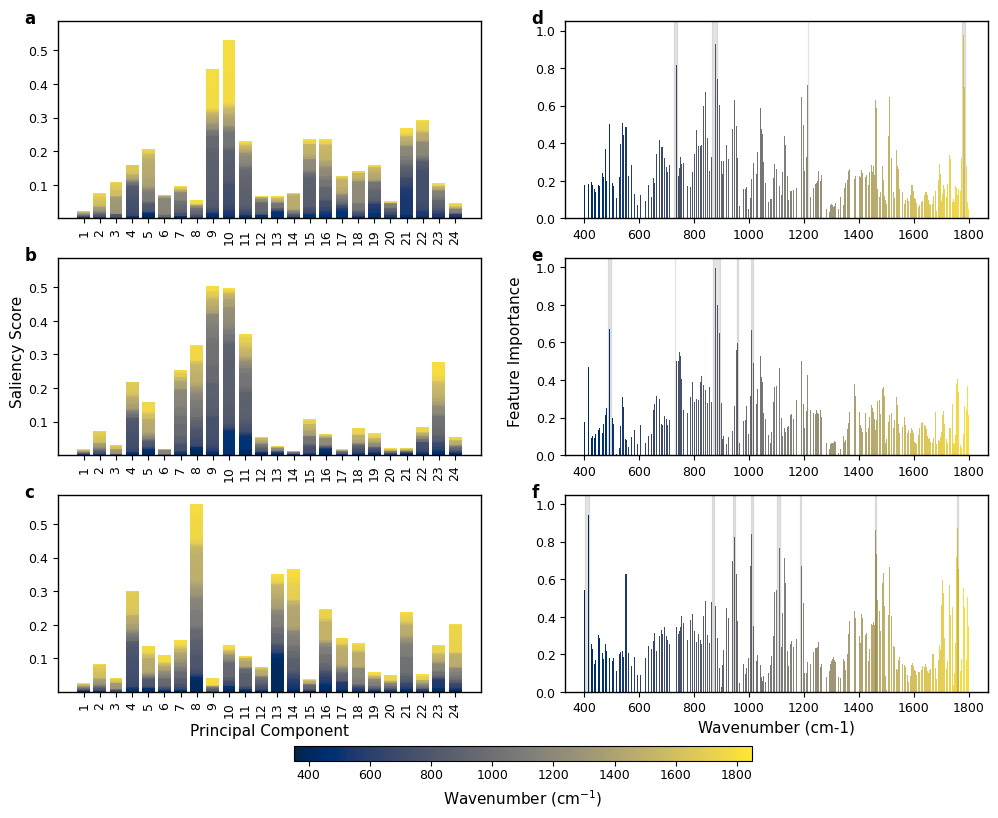

In [7]:
# Fig. 6 - species ANN. Layout: left column (a-c) = saliency score of each of the 24 PCs, drawn as a stacked bar whose colour segments show how that PC's
# saliency is shared among wavenumbers (segment height = saliency x squared loading; each PC loading vector has unit length, so
# the bar height equals the PC's saliency). Right column (d-f) = back-projected wavenumber importance I_j (Eq. 2),
# rescaled to 0-1, with wavenumbers whose z-score is >= 2.5 shaded. One row per outer fold (CV 1-3).
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

# Figure with 3 rows (folds) x 2 columns (PC saliency | wavenumber importance) and a colour bar for wavenumber below
fig = plt.figure(figsize=(12, 10))

outer = GridSpec(
    nrows=4, ncols=2, figure=fig,
    height_ratios=[1, 1, 1, 0.08],
)
outer.update(hspace=0.375, wspace=0.15)

gs = outer[:3, :].subgridspec(nrows=3, ncols=2)

# Wavenumber axis (400-1800 cm-1)
wv = np.array(loaded_data["wavenumber"], dtype=np.float64)

# --- Axes creation ---
# Left column: 3 rows of bar charts
ax_bar1 = fig.add_subplot(gs[0, 0])
ax_bar2 = fig.add_subplot(gs[1, 0], sharex=ax_bar1, sharey=ax_bar1)
ax_bar3 = fig.add_subplot(gs[2, 0], sharex=ax_bar1, sharey=ax_bar1)

# Right column: 3 rows of line plots
ax_line1 = fig.add_subplot(gs[0, 1])
ax_line2 = fig.add_subplot(gs[1, 1], sharex=ax_line1, sharey=ax_line1)
ax_line3 = fig.add_subplot(gs[2, 1], sharex=ax_line1, sharey=ax_line1)

# --- Plotting: Bars (left column) ---
axes_bars = [ax_bar1, ax_bar2, ax_bar3]

for i, ax in enumerate(axes_bars):
    sal = species_interp_scores[folds[i]][1]
    pcw = species_interp_scores[folds[i]][0][:len(sal), :]
    plot_saliency_score(sal, pcw, ax, fig, wv)
    
    ax.grid(False)
    ax.set_xticks(range(1, len(sal) + 1))
    ax.set_xticklabels(labels=range(1, len(sal) + 1), rotation=90)
    ax.tick_params(axis='y')

    if i == 2:
        ax.set_xlabel("Principal Component")

# --- Plotting: Lines (right column) ---
axes_lines = [ax_line1, ax_line2, ax_line3]

cmap = cm.get_cmap('cividis')
norm = plt.Normalize(vmin=np.min(wv)-50, vmax=np.max(wv)+50)
bar_colors = []
mask_comp = []
impact_comp = []

# Colour of each wavenumber bar (cividis scale)
for i in range(len(wv)):
    bar_colors.append(cmap(norm(wv[i])))
        
# Right column: one panel per fold
for i, ax in enumerate(axes_lines):
    sal_score = abs(species_interp_scores[folds[i]][1])
    weights = abs(species_interp_scores[folds[i]][0])
    # Back-projection (manuscript Eq. 2, Section 3.4): importance of wavenumber j = sum over PCs k of saliency_k * |loading_kj|,
    # using that fold's PCA loadings; rescaled to 0-1 (min-max) before z-scoring (z-scores are unaffected by this rescaling).
    cum_interp = []

    for j in range(len(sal_score)):
        cum_interp.append(sal_score[j] * weights[j, :])

    f_int = np.sum(cum_interp, axis=0)
    final_interp = (f_int - np.min(f_int)) / (np.max(f_int) - np.min(f_int))
    ax.bar(wv, final_interp, color = bar_colors)
    
    # Z-score thresholding (Section 3.5): flag wavenumbers whose importance is >= 2.5 standard deviations above the mean
    abs_pc = abs(final_interp)
    mean_weight = np.mean(abs_pc)
    std_weight = np.std(abs_pc)

    z_weight = (abs_pc - mean_weight) / std_weight
    impact_wv = z_weight >= 2.5
    print(wv[impact_wv])
    print("~~~~~~~~~~~~~~~~~~~~~")
    mask = impact_wv
    mask_comp.append(mask)
    impact_comp.append(final_interp)
    # Find contiguous runs of flagged wavenumbers (+1 in the diff = run start, -1 = index after run end) and shade them
    edges = np.diff(impact_wv.astype(int))
    
    start_idx = np.where(edges == 1)[0] + 1
    end_idx = np.where(edges == -1)[0] + 1

    if mask[0]:
        start_idx = np.r_[0, start_idx]
    if mask[-1]:
        end_idx = np.r_[end_idx, len(wv)]  
    for s, e in zip(start_idx, end_idx):
        ax.axvspan(wv[s], wv[e - 1], alpha=0.1, color='k')
    if i == 2:
        ax.set_xlabel("Wavenumber (cm-1)")
#-----------------------------------------------------------------------------------

fig.text(0.5, 0.55, "Feature Importance", va="center", rotation="vertical", fontsize=11)
fig.text(0.085, 0.55, "Saliency Score", va="center", rotation="vertical", fontsize=11)

# --- Make all boxes visible and tidy ---
all_axes = axes_bars + axes_lines
for ax in all_axes:
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.0)


import matplotlib as mpl
plt.subplots_adjust(bottom=0.14)

norm = mpl.colors.Normalize(vmin=np.nanmin(wv)-50, vmax=np.nanmax(wv)+50)
cmap = mpl.cm.get_cmap('cividis')

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

gs_cbar = outer[3, :].subgridspec(nrows=1, ncols=12)

ax_cbar = fig.add_subplot(gs_cbar[0, 3:9])

cbar = fig.colorbar(sm, cax=ax_cbar, orientation='horizontal')
cbar.set_label("Wavenumber (cm$^{-1}$)")
cbar.ax.tick_params()
cbar.ax.xaxis.set_tick_params(pad=2)

labels = ["a", "b", "c", "d", "e", "f"]
axs = [ax_bar1, ax_bar2, ax_bar3, ax_line1, ax_line2, ax_line3]
for ax, label in zip(axs, labels):
    ax.text(-0.08, 1.06, label, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold", va="top")

plt.savefig("Paper and SI images\\Figure_6.jpg", dpi = 400)
plt.show()

# Metabolite Model Interpretability

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
CV 1 - fold selected model architecute
ANN Architecture (hidden):   (20, 10)
ANN activation:              logistic
ANN output activation:       logistic
ANN number of outputs:       1
Input features (n_features): 24
Total layers (incl. in/out): 4
Alpha (L2 penalty):          1e-05
Batch size:                  16
Solver:                      adam
Initial learning rate:       0.001
Learning rate schedule:      constant
Max iterations (allowed):    2000
Iterations run (n_iter_):    459
Final training loss:         0.0054202784159662265
Random state:                42
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
CV 2 - fold selected model architecute
ANN Architecture (hidden):   (20, 5)
ANN activation:              logistic
ANN output activation:       logistic
ANN number of outputs:       1
Input features (n_features): 24
Total layers (incl. in/out): 4


C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\captum\_utils\gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\captum\_utils\gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\captum\_utils\gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(


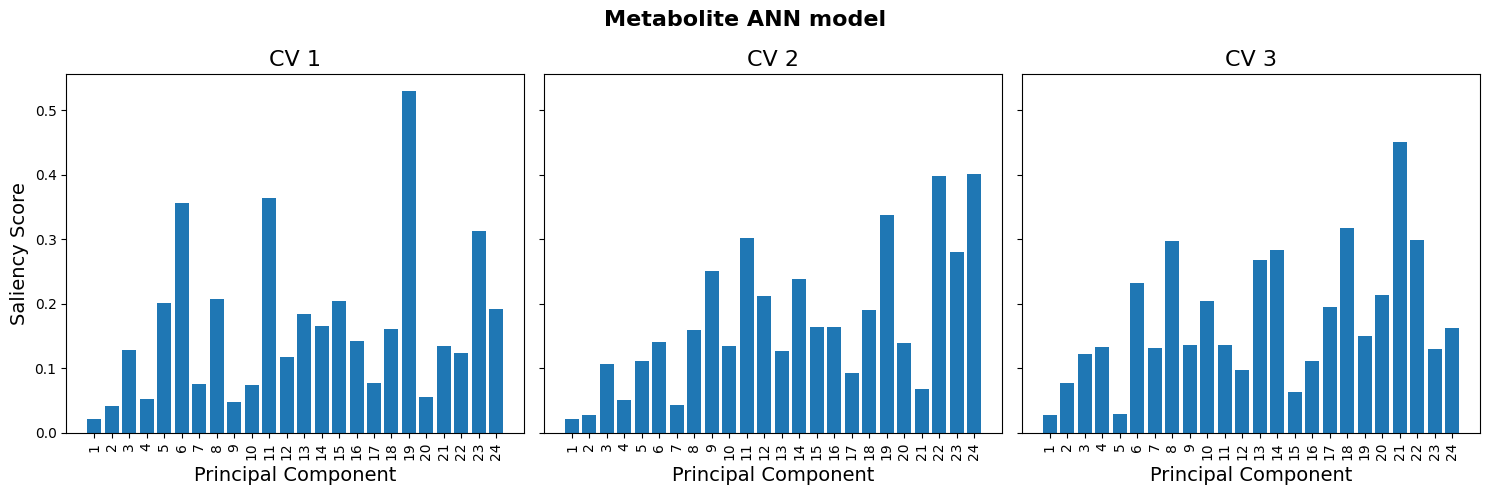

In [8]:
# Benzoate ('metabolites') model: same as the species cell, for the benzoate classifier.
fig, axs = plt.subplots(1, 3, figsize = (15, 5), sharex = True, sharey = True)
ax = axs.ravel()
i = 0
metabolite_interp_scores = {}

for f in folds:
    model_list = ANN_pca_loaded_performance[f][0][24]["metabolites"]
    print("~~"*30)
    print(f +  " - fold selected model architecute")
    # Selected ANN of this fold
    model = model_list[6]
    print("ANN Architecture (hidden):  ", model.hidden_layer_sizes)
    print("ANN activation:             ", model.activation)
    print("ANN output activation:      ", model.out_activation_)
    print("ANN number of outputs:      ", model.n_outputs_)

    # additional details
    print("Input features (n_features):", model.n_features_in_)
    print("Total layers (incl. in/out):", model.n_layers_)
    print("Alpha (L2 penalty):         ", model.alpha)
    print("Batch size:                 ", model.batch_size)
    print("Solver:                     ", model.solver)
    print("Initial learning rate:      ", model.learning_rate_init)
    print("Learning rate schedule:     ", model.learning_rate)   # only used if solver == 'sgd'
    print("Max iterations (allowed):   ", model.max_iter)
    print("Iterations run (n_iter_):   ", model.n_iter_)
    print("Final training loss:        ", model.loss_)
    print("Random state:               ", model.random_state)
    print("~~"*30)
    
    # Saliency per PC for this fold, then plot it
    sal_norm = model_interp(model_list)
    
    ax[i].bar(range(1, len(sal_norm)+1), sal_norm, capsize = 2)
    ax[i].set_xticks(range(1, len(sal_norm)+1))
    ax[i].set_xticklabels(labels = range(1, len(sal_norm)+1), rotation = 90, fontsize = 10)
    ax[i].tick_params(axis='y', labelsize=10)
    ax[i].set_xlabel("Principal Component", fontsize = 14)
    ax[i].set_title(f,fontsize = 16)
    if i ==0:
        ax[i].set_ylabel("Saliency Score", fontsize = 14)
    i += 1
    metabolite_interp_scores[f] = [ANN_pca_loaded_performance[f][1].components_, sal_norm]
    
fig.suptitle("Metabolite ANN model", fontsize = 16, fontweight = "bold")
plt.tight_layout()

C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')


[ 486.  487.  490.  491.  492.  865.  866.  870.  871.  872.  873.  880.
  884.  910.  911.  946.  947.  948.  949.  950. 1034. 1190. 1191. 1212.
 1213. 1214. 1459. 1460. 1461. 1462. 1463. 1464.]
~~~~~~~~~~~~~~~~~~~~
[ 407.  410.  411.  412.  415.  416.  729.  730.  731.  734.  735.  736.
  866.  870.  871.  872.  873.  877. 1211. 1212. 1213. 1214. 1215. 1468.
 1470. 1472. 1473. 1474. 1736. 1737. 1738. 1739. 1740. 1741. 1795. 1796.
 1797.]
~~~~~~~~~~~~~~~~~~~~
[ 410.  411.  412.  550.  554.  555.  942.  948.  949.  950.  954. 1006.
 1007. 1008. 1009. 1013. 1014. 1102. 1103. 1108. 1109. 1110. 1111. 1124.
 1129. 1130. 1131. 1132. 1186. 1187. 1188. 1189. 1190. 1191. 1459. 1460.
 1461. 1462. 1463. 1464.]
~~~~~~~~~~~~~~~~~~~~


C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\3035540489.py:117: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('cividis')


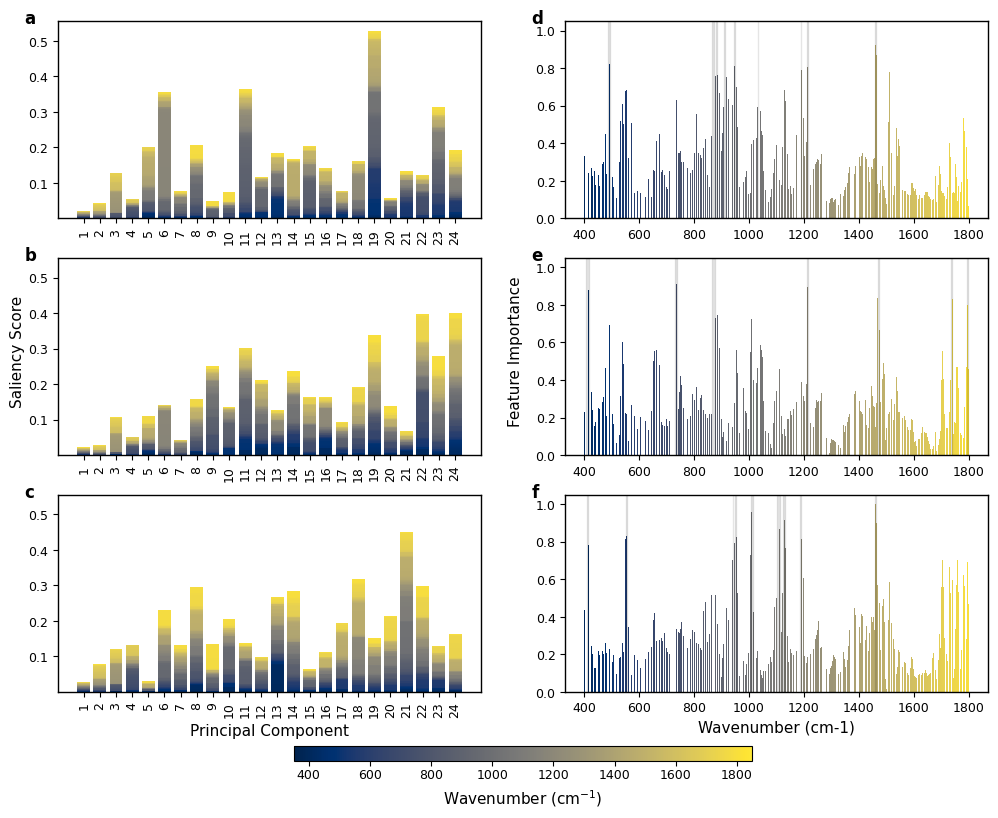

In [9]:
# Fig. 7 - benzoate ANN. Layout: left column (a-c) = saliency score of each of the 24 PCs, drawn as a stacked bar whose colour segments show how that PC's
# saliency is shared among wavenumbers (segment height = saliency x squared loading; each PC loading vector has unit length, so
# the bar height equals the PC's saliency). Right column (d-f) = back-projected wavenumber importance I_j (Eq. 2),
# rescaled to 0-1, with wavenumbers whose z-score is >= 2.5 shaded. One row per outer fold (CV 1-3).
# Uses cmap and norm defined in the Fig. 6 cell above.
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

fig = plt.figure(figsize=(12, 10))

outer = GridSpec(
    nrows=4, ncols=2, figure=fig,
    height_ratios=[1, 1, 1, 0.08],
)
outer.update(hspace=0.375, wspace=0.15)

gs = outer[:3, :].subgridspec(nrows=3, ncols=2)

wv = np.array(loaded_data["wavenumber"], dtype=np.float64)

# --- Axes creation ---
# Left column: 3 rows of bar charts
ax_bar1 = fig.add_subplot(gs[0, 0])
ax_bar2 = fig.add_subplot(gs[1, 0], sharex=ax_bar1, sharey=ax_bar1)
ax_bar3 = fig.add_subplot(gs[2, 0], sharex=ax_bar1, sharey=ax_bar1)

# Right column: 3 rows of line plots
ax_line1 = fig.add_subplot(gs[0, 1])
ax_line2 = fig.add_subplot(gs[1, 1], sharex=ax_line1, sharey=ax_line1)
ax_line3 = fig.add_subplot(gs[2, 1], sharex=ax_line1, sharey=ax_line1)

# --- Plotting: Bars (left column) ---
axes_bars = [ax_bar1, ax_bar2, ax_bar3]

for i, ax in enumerate(axes_bars):
    sal = metabolite_interp_scores[folds[i]][1]
    pcw = metabolite_interp_scores[folds[i]][0][:len(sal), :]
    plot_saliency_score(sal, pcw, ax, fig, wv)
    
    ax.grid(False)
    ax.set_xticks(range(1, len(sal) + 1))
    ax.set_xticklabels(labels=range(1, len(sal) + 1), rotation=90)
    ax.tick_params(axis='y')

    if i == 2:
        ax.set_xlabel("Principal Component")

# --- Plotting: Lines (right column) ---
# Right column: one panel per fold
axes_lines = [ax_line1, ax_line2, ax_line3]
bar_colors = []
mask_comp = []
impact_comp = []

for i in range(len(wv)):
    bar_colors.append(cmap(norm(wv[i])))

for i, ax in enumerate(axes_lines):
    sal_score = metabolite_interp_scores[folds[i]][1]
    weights = abs(metabolite_interp_scores[folds[i]][0])
    # Back-projection (manuscript Eq. 2, Section 3.4): importance of wavenumber j = sum over PCs k of saliency_k * |loading_kj|,
    # using that fold's PCA loadings; rescaled to 0-1 (min-max) before z-scoring (z-scores are unaffected by this rescaling).
    cum_interp = []

    for j in range(len(sal_score)):
        cum_interp.append(sal_score[j] * weights[j, :])

    f_int = np.sum(cum_interp, axis=0)
    final_interp = (f_int - np.min(f_int)) / (np.max(f_int) - np.min(f_int))
    ax.bar(wv, final_interp, color = bar_colors)
    
    # Z-score thresholding (Section 3.5): flag wavenumbers whose importance is >= 2.5 standard deviations above the mean
    abs_pc = abs(final_interp)
    mean_weight = np.mean(abs_pc)
    std_weight = np.std(abs_pc)

    z_weight = (abs_pc - mean_weight) / std_weight
    impact_wv = z_weight >= 2.5
    print(wv[impact_wv])
    print("~~~~~~~~~~~~~~~~~~~~")
    
    mask = impact_wv
    mask_comp.append(mask)
    impact_comp.append(final_interp)
    
    # Find contiguous runs of flagged wavenumbers (+1 in the diff = run start, -1 = index after run end) and shade them
    edges = np.diff(impact_wv.astype(int))
    
    start_idx = np.where(edges == 1)[0] + 1
    end_idx = np.where(edges == -1)[0] + 1

    if mask[0]:
        start_idx = np.r_[0, start_idx]
    if mask[-1]:
        end_idx = np.r_[end_idx, len(wv)]  
    for s, e in zip(start_idx, end_idx):
        ax.axvspan(wv[s], wv[e - 1], alpha=0.1, color='k')
    if i == 2:
        ax.set_xlabel("Wavenumber (cm-1)")

#-----------------------------------------------------------------------------------

fig.text(0.5, 0.55, "Feature Importance", va="center", rotation="vertical", fontsize=11)
fig.text(0.085, 0.55, "Saliency Score", va="center", rotation="vertical", fontsize=11)

# --- Make all boxes visible and tidy ---
all_axes = axes_bars + axes_lines
for ax in all_axes:
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.0)

import matplotlib as mpl
plt.subplots_adjust(bottom=0.14)

norm = mpl.colors.Normalize(vmin=np.nanmin(wv)-50, vmax=np.nanmax(wv)+50)
cmap = mpl.cm.get_cmap('cividis')

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

gs_cbar = outer[3, :].subgridspec(nrows=1, ncols=12)

ax_cbar = fig.add_subplot(gs_cbar[0, 3:9])

cbar = fig.colorbar(sm, cax=ax_cbar, orientation='horizontal')
cbar.set_label("Wavenumber (cm$^{-1}$)")
cbar.ax.tick_params()
cbar.ax.xaxis.set_tick_params(pad=2)

labels = ["a", "b", "c", "d", "e", "f"]
axs = [ax_bar1, ax_bar2, ax_bar3, ax_line1, ax_line2, ax_line3]
for ax, label in zip(axs, labels):
    ax.text(-0.08, 1.06, label, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold", va="top")

plt.savefig("Paper and SI images\\Figure_7.jpg", dpi = 400)
plt.show()

# Age Model Interpretability

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
CV 1 - fold selected model architecute
ANN Architecture (hidden):   (10, 5)
ANN activation:              relu
ANN output activation:       softmax
ANN number of outputs:       3
Input features (n_features): 24
Total layers (incl. in/out): 4
Alpha (L2 penalty):          0.1
Batch size:                  16
Solver:                      adam
Initial learning rate:       0.001
Learning rate schedule:      constant
Max iterations (allowed):    2000
Iterations run (n_iter_):    498
Final training loss:         0.07104507012669031
Random state:                42
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
CV 2 - fold selected model architecute
ANN Architecture (hidden):   (5,)
ANN activation:              relu
ANN output activation:       softmax
ANN number of outputs:       3
Input features (n_features): 24
Total layers (incl. in/out): 3
Alpha (L2 penalty)

C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\captum\_utils\gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\torch\nn\modules\module.py:1751: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)
C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\captum\_utils\gradient.py:57: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  warnings.warn(
C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\torch\nn\modules\module.py:1751: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)
C:\Users\slaxminarayan3\AppData\Local\

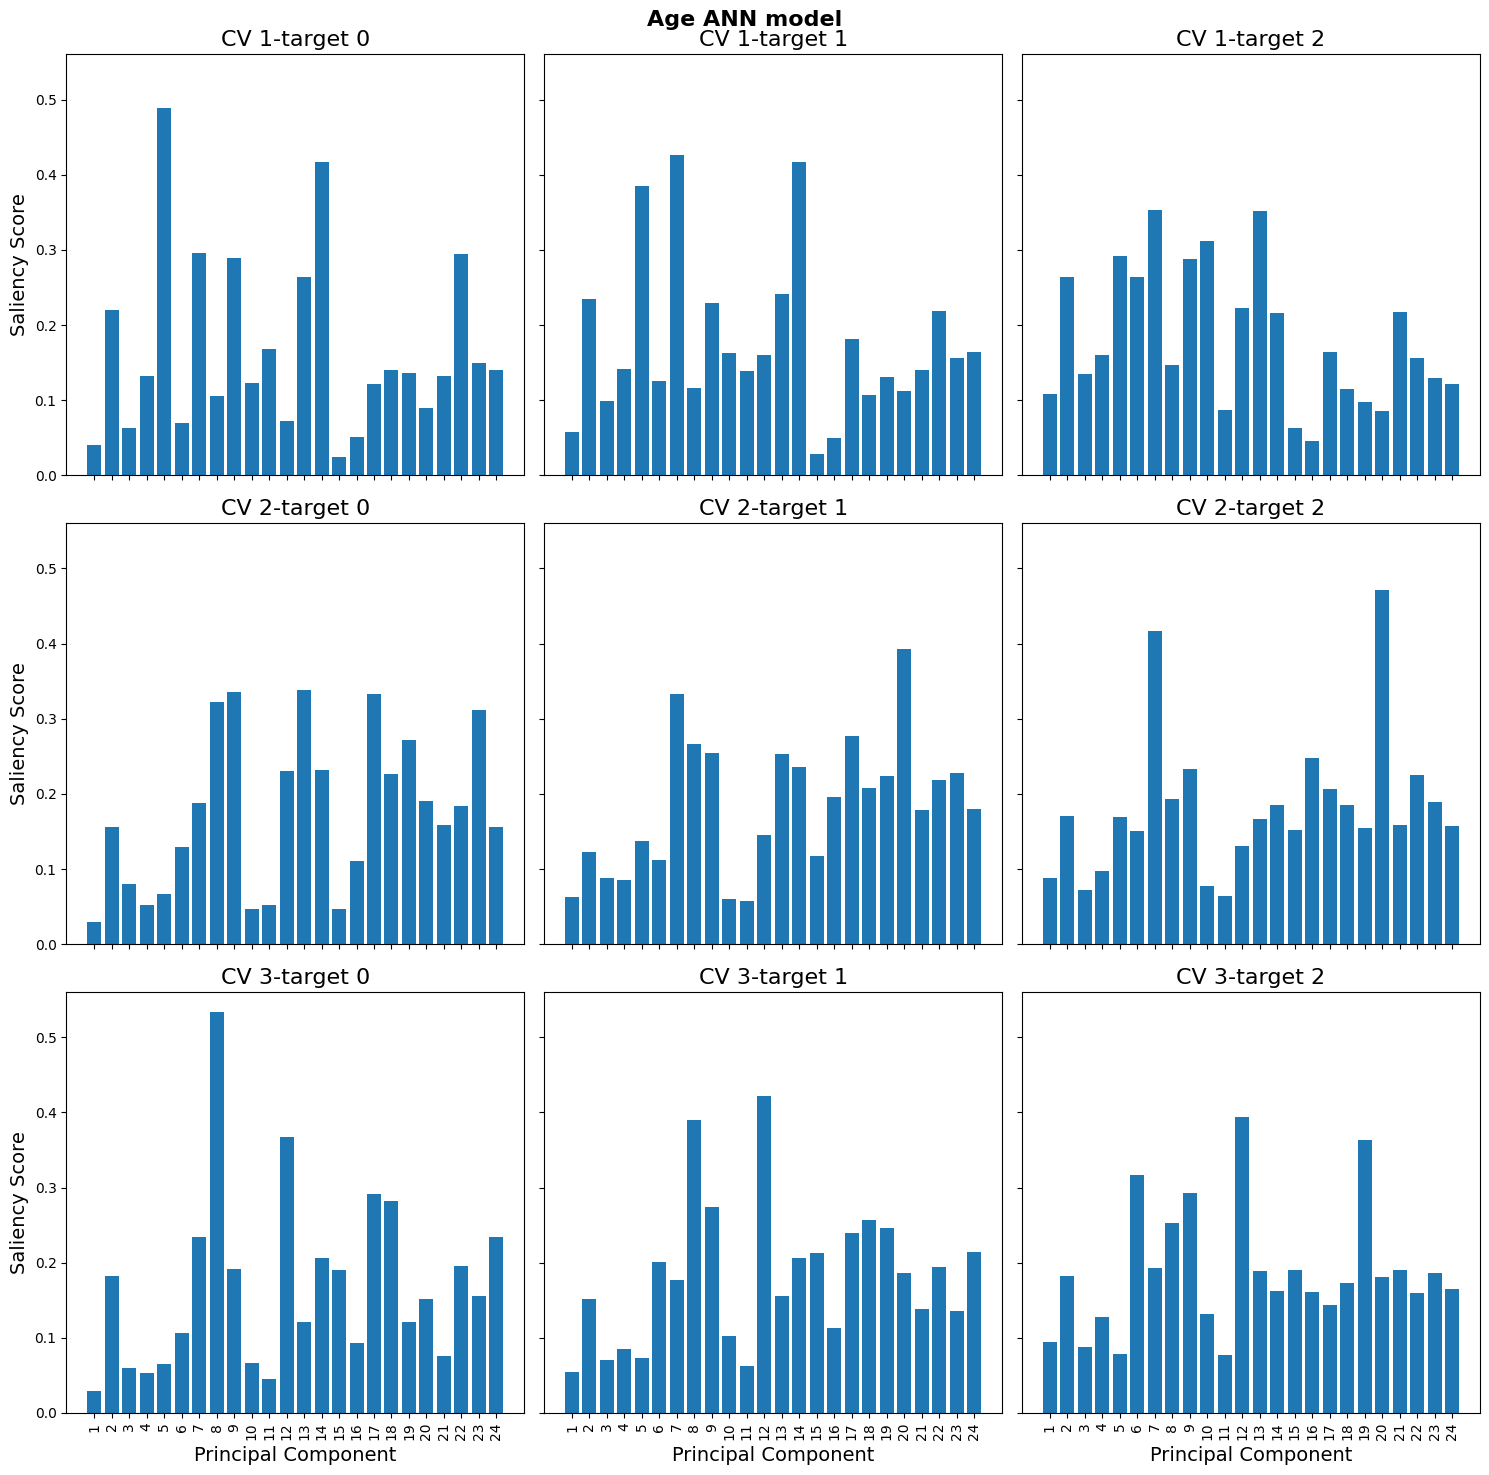

In [10]:
# Age model (3 outputs): saliency is computed separately for each output class (target 0 = 5 h, 1 = 24 h, 2 = 48 h) for every fold.
# Results are stored in age5_/age24_/age48_interp_scores. Grid: rows = folds, columns = target class.
age5_interp_scores = {}
age24_interp_scores = {}
age48_interp_scores = {}
age_dict = [age5_interp_scores, age24_interp_scores, age48_interp_scores]

fig, axs = plt.subplots(3,3, figsize = (15,15), sharex = True, sharey = True)

# i = output class (0 = 5 h, 1 = 24 h, 2 = 48 h); f = fold
for i in range(3):
    for f in range(len(folds)):
        model_list = ANN_pca_loaded_performance[folds[f]][0][24]["age"]
        if i == 0:
                print("~~"*30)
                print(folds[f] +  " - fold selected model architecute")
                model = model_list[6]
                print("ANN Architecture (hidden):  ", model.hidden_layer_sizes)
                print("ANN activation:             ", model.activation)
                print("ANN output activation:      ", model.out_activation_)
                print("ANN number of outputs:      ", model.n_outputs_)

                # additional details
                print("Input features (n_features):", model.n_features_in_)
                print("Total layers (incl. in/out):", model.n_layers_)
                print("Alpha (L2 penalty):         ", model.alpha)
                print("Batch size:                 ", model.batch_size)
                print("Solver:                     ", model.solver)
                print("Initial learning rate:      ", model.learning_rate_init)
                print("Learning rate schedule:     ", model.learning_rate)   # only used if solver == 'sgd'
                print("Max iterations (allowed):   ", model.max_iter)
                print("Iterations run (n_iter_):   ", model.n_iter_)
                print("Final training loss:        ", model.loss_)
                print("Random state:               ", model.random_state)
                print("~~"*30)
                
        # Saliency of output class i for this fold's age model
        sal_norm = model_interp(model_list, i)
        age_dict[i][folds[f]] = [ANN_pca_loaded_performance[folds[f]][1].components_, sal_norm]
        axs[f, i].bar(range(1, len(sal_norm)+1), sal_norm)
        axs[f, i].set_xticks(range(1, len(sal_norm)+1))
        axs[f, i].set_xticklabels(labels = range(1, len(sal_norm)+1), rotation = 90, fontsize = 10)
        axs[f, i].tick_params(axis='y', labelsize=10)
        if f == 2:
            axs[f, i].set_xlabel("Principal Component", fontsize = 14)
        axs[f, i].set_title(folds[f] + "-target "+str(i) ,fontsize = 16)
        if i == 0:
            axs[f, i].set_ylabel("Saliency Score", fontsize = 14)
fig.suptitle("Age ANN model", fontsize = 16, fontweight = "bold")
plt.tight_layout()

C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')


[ 486.  487.  490.  491.  730.  731.  734.  735.  736.  879.  880. 1458.
 1459. 1460. 1461. 1462. 1463. 1464. 1465. 1466.]
~~~~~~~~~~~~~~~~~~~~
[ 407.  410.  411.  412.  415.  416.  730.  731.  734.  735.  870.  871.
  872.  873.  877. 1008. 1009. 1211. 1212. 1213. 1214. 1215. 1216. 1736.
 1737. 1738. 1739. 1740. 1741. 1795. 1796. 1797.]
~~~~~~~~~~~~~~~~~~~~
[ 410.  411.  412.  550.  554.  947.  948.  949.  950.  954. 1186. 1187.
 1188. 1189. 1190. 1191. 1459. 1460. 1461. 1462. 1463. 1464. 1465.]
~~~~~~~~~~~~~~~~~~~~


C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\2402772883.py:116: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('cividis')


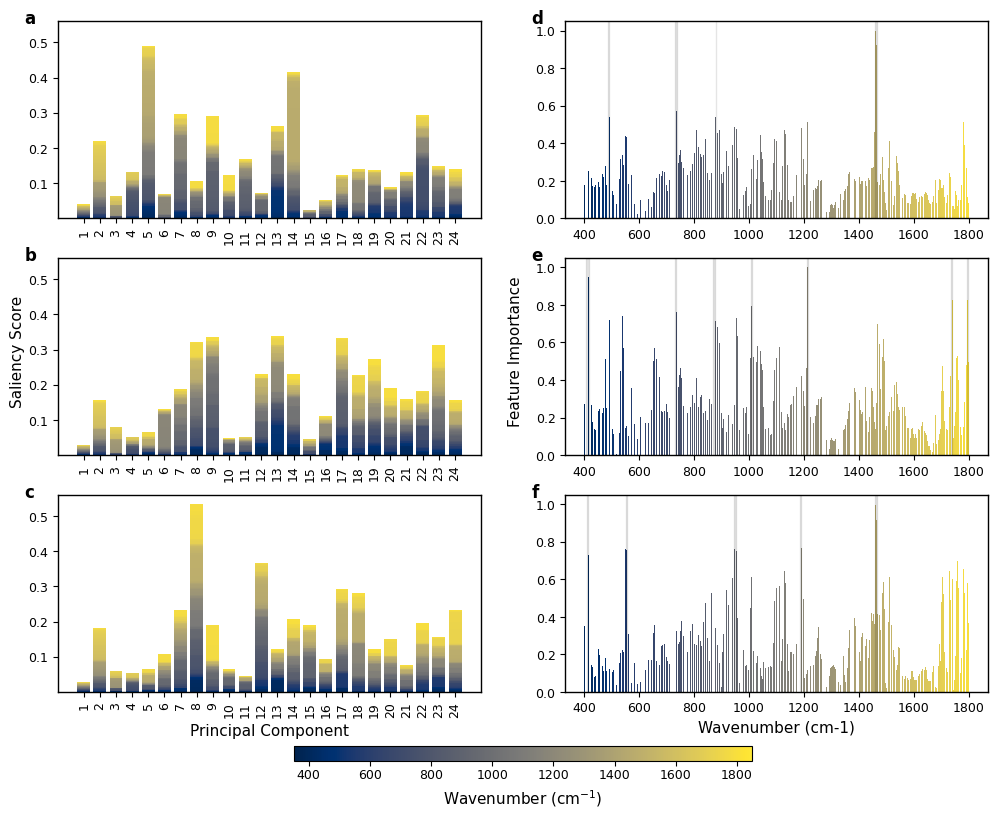

In [11]:
# Fig. S2 - age ANN, class 5 h. Layout: left column (a-c) = saliency score of each of the 24 PCs, drawn as a stacked bar whose colour segments show how that PC's
# saliency is shared among wavenumbers (segment height = saliency x squared loading; each PC loading vector has unit length, so
# the bar height equals the PC's saliency). Right column (d-f) = back-projected wavenumber importance I_j (Eq. 2),
# rescaled to 0-1, with wavenumbers whose z-score is >= 2.5 shaded. One row per outer fold (CV 1-3).
# Uses cmap and norm defined in the Fig. 6 cell above.
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

fig = plt.figure(figsize=(12, 10))

outer = GridSpec(
    nrows=4, ncols=2, figure=fig,
    height_ratios=[1, 1, 1, 0.08],
)
outer.update(hspace=0.375, wspace=0.15)

gs = outer[:3, :].subgridspec(nrows=3, ncols=2)

wv = np.array(loaded_data["wavenumber"], dtype=np.float64)

# --- Axes creation ---
# Left column: 3 rows of bar charts
ax_bar1 = fig.add_subplot(gs[0, 0])
ax_bar2 = fig.add_subplot(gs[1, 0], sharex=ax_bar1, sharey=ax_bar1)
ax_bar3 = fig.add_subplot(gs[2, 0], sharex=ax_bar1, sharey=ax_bar1)

# Right column: 3 rows of line plots
ax_line1 = fig.add_subplot(gs[0, 1])
ax_line2 = fig.add_subplot(gs[1, 1], sharex=ax_line1, sharey=ax_line1)
ax_line3 = fig.add_subplot(gs[2, 1], sharex=ax_line1, sharey=ax_line1)

# --- Plotting: Bars (left column) ---
axes_bars = [ax_bar1, ax_bar2, ax_bar3]

# Left column: PC saliency (stacked by wavenumber) for the 5 h class
for i, ax in enumerate(axes_bars):
    sal = age5_interp_scores[folds[i]][1]
    pcw = age5_interp_scores[folds[i]][0][:len(sal), :]
    plot_saliency_score(sal, pcw, ax, fig, wv)
    
    ax.grid(False)
    ax.set_xticks(range(1, len(sal) + 1))
    ax.set_xticklabels(labels=range(1, len(sal) + 1), rotation=90)
    ax.tick_params(axis='y')

    if i == 2:
        ax.set_xlabel("Principal Component")

# --- Plotting: Lines (right column) ---
axes_lines = [ax_line1, ax_line2, ax_line3]
bar_colors = []
mask5_comp = []

for i in range(len(wv)):
    bar_colors.append(cmap(norm(wv[i])))

# Right column: importance per wavenumber for the 5 h class
for i, ax in enumerate(axes_lines):
    sal_score = age5_interp_scores[folds[i]][1]
    weights = abs(age5_interp_scores[folds[i]][0])
    cum_interp = []

    # Back-projection (manuscript Eq. 2, Section 3.4): importance of wavenumber j = sum over PCs k of saliency_k * |loading_kj|,
    # using that fold's PCA loadings; rescaled to 0-1 (min-max) before z-scoring (z-scores are unaffected by this rescaling).
    for j in range(len(sal_score)):
        cum_interp.append(sal_score[j] * weights[j, :])

    f_int = np.sum(cum_interp, axis=0)
    final_interp = (f_int - np.min(f_int)) / (np.max(f_int) - np.min(f_int))
    
    ax.bar(wv, final_interp, color = bar_colors)

    # Z-score thresholding (Section 3.5): flag wavenumbers whose importance is >= 2.5 standard deviations above the mean
    abs_pc = abs(final_interp)
    mean_weight = np.mean(abs_pc)
    std_weight = np.std(abs_pc)

    z_weight = (abs_pc - mean_weight) / std_weight
    impact_wv = z_weight >= 2.5
    print(wv[impact_wv])
    print("~~~~~~~~~~~~~~~~~~~~")
    
    mask = impact_wv
    # Find contiguous runs of flagged wavenumbers (+1 in the diff = run start, -1 = index after run end) and shade them
    edges = np.diff(impact_wv.astype(int))
    mask5_comp.append(mask)
    
    start_idx = np.where(edges == 1)[0] + 1
    end_idx = np.where(edges == -1)[0] + 1

    if mask[0]:
        start_idx = np.r_[0, start_idx]
    if mask[-1]:
        end_idx = np.r_[end_idx, len(wv)]  
    for s, e in zip(start_idx, end_idx):
        ax.axvspan(wv[s], wv[e - 1], alpha=0.1, color='k')
    if i == 2:
        ax.set_xlabel("Wavenumber (cm-1)")

#-----------------------------------------------------------------------------------

fig.text(0.5, 0.55, "Feature Importance", va="center", rotation="vertical", fontsize=11)
fig.text(0.085, 0.55, "Saliency Score", va="center", rotation="vertical", fontsize=11)

# --- Make all boxes visible and tidy ---
all_axes = axes_bars + axes_lines
for ax in all_axes:
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.0)


import matplotlib as mpl
plt.subplots_adjust(bottom=0.14)

norm = mpl.colors.Normalize(vmin=np.nanmin(wv)-50, vmax=np.nanmax(wv)+50)
cmap = mpl.cm.get_cmap('cividis')

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

gs_cbar = outer[3, :].subgridspec(nrows=1, ncols=12)

ax_cbar = fig.add_subplot(gs_cbar[0, 3:9])

cbar = fig.colorbar(sm, cax=ax_cbar, orientation='horizontal')
cbar.set_label("Wavenumber (cm$^{-1}$)")
cbar.ax.tick_params()
cbar.ax.xaxis.set_tick_params(pad=2)

labels = ["a", "b", "c", "d", "e", "f"]
axs = [ax_bar1, ax_bar2, ax_bar3, ax_line1, ax_line2, ax_line3]
for ax, label in zip(axs, labels):
    ax.text(-0.08, 1.06, label, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold", va="top")

plt.savefig("Paper and SI images\\Figure_S2.jpg", dpi = 400)
plt.show()

C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')


[ 486.  487.  490.  491.  492.  734.  880.  946.  947.  948.  949.  950.
 1458. 1459. 1460. 1461. 1462. 1463. 1464. 1465.]
~~~~~~~~~~~~~~~~~~~~
[ 407.  410.  411.  412.  415.  416.  729.  730.  731.  734.  735.  736.
  871.  872.  955. 1008. 1009. 1013. 1211. 1212. 1213. 1214. 1215. 1216.
 1470. 1472. 1473. 1736. 1737. 1738. 1739. 1740. 1741. 1794. 1795. 1796.
 1797.]
~~~~~~~~~~~~~~~~~~~~
[ 410.  411.  412.  942.  946.  947.  948.  949.  950.  954. 1130. 1131.
 1186. 1187. 1188. 1189. 1190. 1191. 1459. 1460. 1461. 1462. 1463. 1464.]
~~~~~~~~~~~~~~~~~~~~


C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\4246222618.py:116: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('cividis')


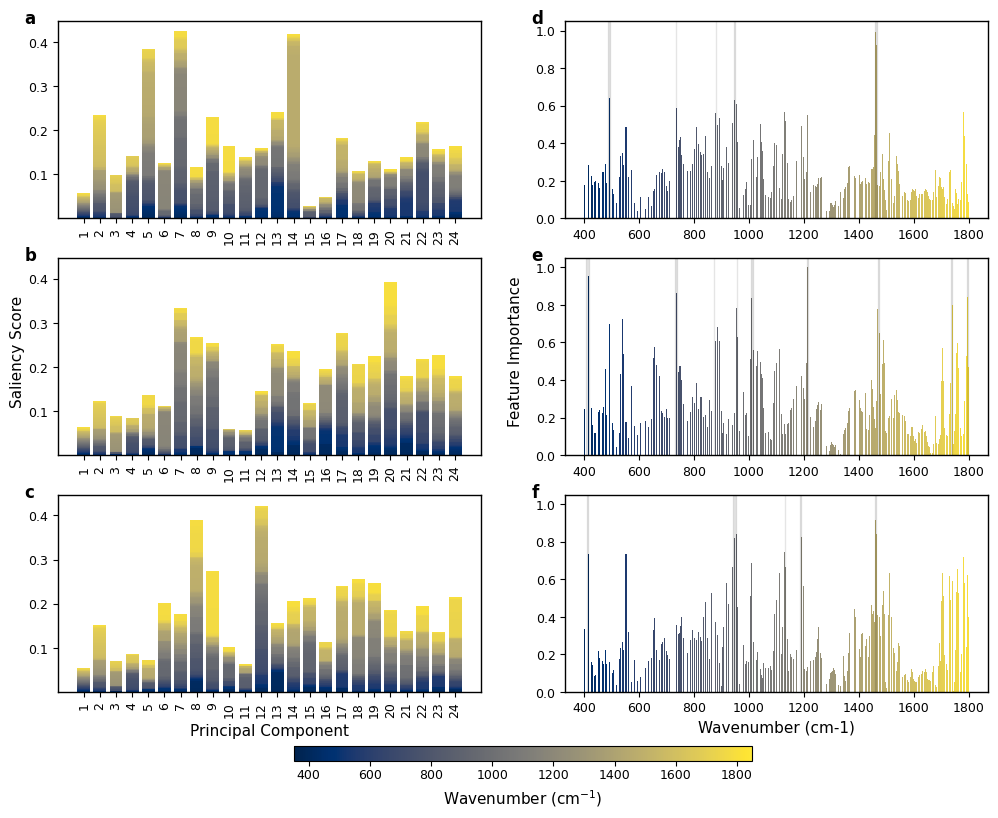

In [12]:
# Fig. S3 - age ANN, class 24 h. Layout: left column (a-c) = saliency score of each of the 24 PCs, drawn as a stacked bar whose colour segments show how that PC's
# saliency is shared among wavenumbers (segment height = saliency x squared loading; each PC loading vector has unit length, so
# the bar height equals the PC's saliency). Right column (d-f) = back-projected wavenumber importance I_j (Eq. 2),
# rescaled to 0-1, with wavenumbers whose z-score is >= 2.5 shaded. One row per outer fold (CV 1-3).
# Uses cmap and norm defined in the Fig. 6 cell above.
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

fig = plt.figure(figsize=(12, 10))

outer = GridSpec(
    nrows=4, ncols=2, figure=fig,
    height_ratios=[1, 1, 1, 0.08],
)
outer.update(hspace=0.375, wspace=0.15)

gs = outer[:3, :].subgridspec(nrows=3, ncols=2)

wv = np.array(loaded_data["wavenumber"], dtype=np.float64)

# --- Axes creation ---
# Left column: 3 rows of bar charts
ax_bar1 = fig.add_subplot(gs[0, 0])
ax_bar2 = fig.add_subplot(gs[1, 0], sharex=ax_bar1, sharey=ax_bar1)
ax_bar3 = fig.add_subplot(gs[2, 0], sharex=ax_bar1, sharey=ax_bar1)

# Right column: 3 rows of line plots
ax_line1 = fig.add_subplot(gs[0, 1])
ax_line2 = fig.add_subplot(gs[1, 1], sharex=ax_line1, sharey=ax_line1)
ax_line3 = fig.add_subplot(gs[2, 1], sharex=ax_line1, sharey=ax_line1)

# --- Plotting: Bars (left column) ---
axes_bars = [ax_bar1, ax_bar2, ax_bar3]

# Left column: PC saliency (stacked by wavenumber) for the 24 h class
for i, ax in enumerate(axes_bars):
    sal = age24_interp_scores[folds[i]][1]
    pcw = age24_interp_scores[folds[i]][0][:len(sal), :]
    plot_saliency_score(sal, pcw, ax, fig, wv)
    
    ax.grid(False)
    ax.set_xticks(range(1, len(sal) + 1))
    ax.set_xticklabels(labels=range(1, len(sal) + 1), rotation=90)
    ax.tick_params(axis='y')

    if i == 2:
        ax.set_xlabel("Principal Component")

# --- Plotting: Lines (right column) ---
axes_lines = [ax_line1, ax_line2, ax_line3]
bar_colors = []
mask24_comp = []

for i in range(len(wv)):
    bar_colors.append(cmap(norm(wv[i])))

# Right column: importance per wavenumber for the 24 h class
for i, ax in enumerate(axes_lines):
    sal_score = age24_interp_scores[folds[i]][1]
    weights = abs(age24_interp_scores[folds[i]][0])
    cum_interp = []

    # Back-projection (manuscript Eq. 2, Section 3.4): importance of wavenumber j = sum over PCs k of saliency_k * |loading_kj|,
    # using that fold's PCA loadings; rescaled to 0-1 (min-max) before z-scoring (z-scores are unaffected by this rescaling).
    for j in range(len(sal_score)):
        cum_interp.append(sal_score[j] * weights[j, :])

    f_int = np.sum(cum_interp, axis=0)
    final_interp = (f_int - np.min(f_int)) / (np.max(f_int) - np.min(f_int))
    
    ax.bar(wv, final_interp, color = bar_colors)

    # Z-score thresholding (Section 3.5): flag wavenumbers whose importance is >= 2.5 standard deviations above the mean
    abs_pc = abs(final_interp)
    mean_weight = np.mean(abs_pc)
    std_weight = np.std(abs_pc)

    z_weight = (abs_pc - mean_weight) / std_weight
    impact_wv = z_weight >= 2.5
    print(wv[impact_wv])
    print("~~~~~~~~~~~~~~~~~~~~")
    
    mask = impact_wv
    # Find contiguous runs of flagged wavenumbers (+1 in the diff = run start, -1 = index after run end) and shade them
    edges = np.diff(impact_wv.astype(int))
    mask24_comp.append(mask)
    
    start_idx = np.where(edges == 1)[0] + 1
    end_idx = np.where(edges == -1)[0] + 1

    if mask[0]:
        start_idx = np.r_[0, start_idx]
    if mask[-1]:
        end_idx = np.r_[end_idx, len(wv)]  
    for s, e in zip(start_idx, end_idx):
        ax.axvspan(wv[s], wv[e - 1], alpha=0.1, color='k')
    if i == 2:
        ax.set_xlabel("Wavenumber (cm-1)")

#-----------------------------------------------------------------------------------

fig.text(0.5, 0.55, "Feature Importance", va="center", rotation="vertical", fontsize=11)
fig.text(0.085, 0.55, "Saliency Score", va="center", rotation="vertical", fontsize=11)

# --- Make all boxes visible and tidy ---
all_axes = axes_bars + axes_lines
for ax in all_axes:
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.0)


import matplotlib as mpl
plt.subplots_adjust(bottom=0.14)

norm = mpl.colors.Normalize(vmin=np.nanmin(wv)-50, vmax=np.nanmax(wv)+50)
cmap = mpl.cm.get_cmap('cividis')

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

gs_cbar = outer[3, :].subgridspec(nrows=1, ncols=12)

ax_cbar = fig.add_subplot(gs_cbar[0, 3:9])

cbar = fig.colorbar(sm, cax=ax_cbar, orientation='horizontal')
cbar.set_label("Wavenumber (cm$^{-1}$)")
cbar.ax.tick_params()
cbar.ax.xaxis.set_tick_params(pad=2)

labels = ["a", "b", "c", "d", "e", "f"]
axs = [ax_bar1, ax_bar2, ax_bar3, ax_line1, ax_line2, ax_line3]
for ax, label in zip(axs, labels):
    ax.text(-0.08, 1.06, label, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold", va="top")

plt.savefig("Paper and SI images\\Figure_S3.jpg", dpi = 400)
plt.show()

C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')
C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\810144578.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('cividis')


[ 486.  487.  490.  491.  492.  873.  877.  878.  879.  880.  884.  941.
  942.  946.  947.  948.  949.  950. 1187. 1188. 1459. 1460. 1461. 1462.
 1463. 1464. 1777. 1778. 1779. 1780. 1781. 1782. 1783. 1784.]
~~~~~~~~~~~~~~~~~~~~
[ 407.  410.  411.  412.  415.  416.  729.  730.  731.  734.  735.  736.
  954.  955.  956. 1008. 1009. 1013. 1014. 1211. 1212. 1213. 1214. 1215.
 1468. 1470. 1472. 1473. 1737. 1738. 1739. 1740. 1794. 1795. 1796.]
~~~~~~~~~~~~~~~~~~~~
[ 410.  941.  942.  946.  947.  948.  949.  950.  954. 1009. 1103. 1108.
 1109. 1110. 1129. 1130. 1131. 1132. 1186. 1187. 1188. 1189. 1190. 1191.
 1197. 1461. 1462. 1780. 1781. 1782.]
~~~~~~~~~~~~~~~~~~~~


C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_14452\2217444507.py:116: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('cividis')


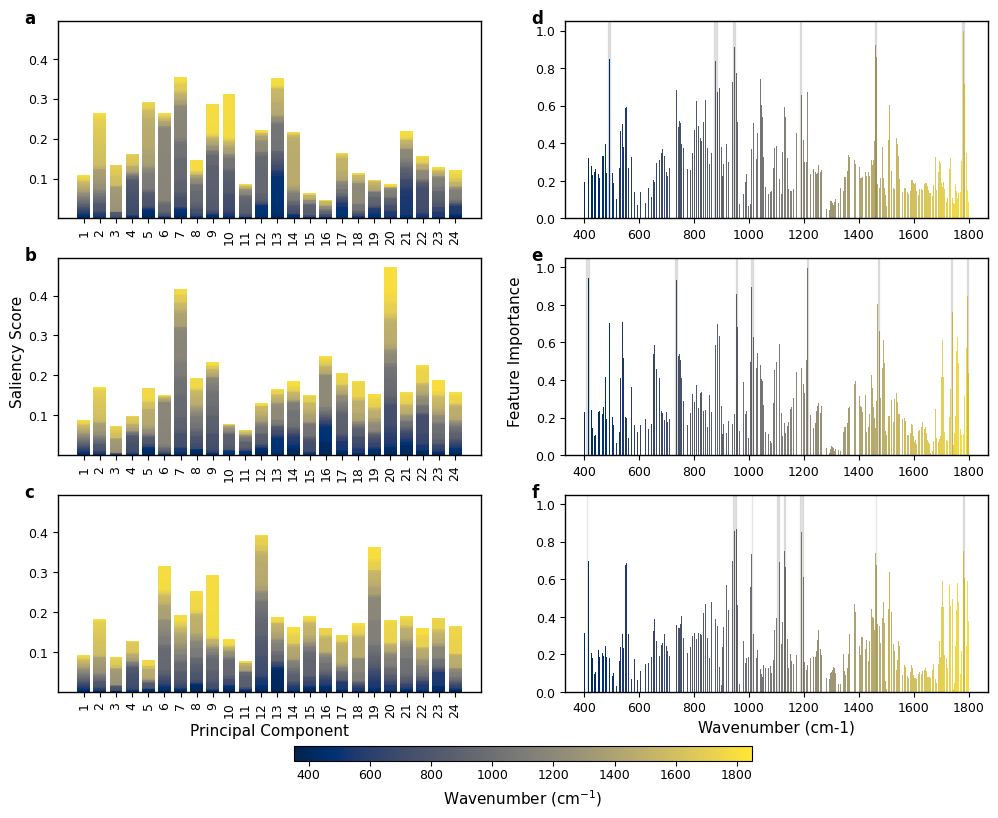

In [13]:
# Fig. S4 - age ANN, class 48 h. Layout: left column (a-c) = saliency score of each of the 24 PCs, drawn as a stacked bar whose colour segments show how that PC's
# saliency is shared among wavenumbers (segment height = saliency x squared loading; each PC loading vector has unit length, so
# the bar height equals the PC's saliency). Right column (d-f) = back-projected wavenumber importance I_j (Eq. 2),
# rescaled to 0-1, with wavenumbers whose z-score is >= 2.5 shaded. One row per outer fold (CV 1-3).
# Uses cmap and norm defined in the Fig. 6 cell above.
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

fig = plt.figure(figsize=(12, 10))

outer = GridSpec(
    nrows=4, ncols=2, figure=fig,
    height_ratios=[1, 1, 1, 0.08],
)
outer.update(hspace=0.375, wspace=0.15)

gs = outer[:3, :].subgridspec(nrows=3, ncols=2)

wv = np.array(loaded_data["wavenumber"], dtype=np.float64)

# --- Axes creation ---
# Left column: 3 rows of bar charts
ax_bar1 = fig.add_subplot(gs[0, 0])
ax_bar2 = fig.add_subplot(gs[1, 0], sharex=ax_bar1, sharey=ax_bar1)
ax_bar3 = fig.add_subplot(gs[2, 0], sharex=ax_bar1, sharey=ax_bar1)

# Right column: 3 rows of line plots
ax_line1 = fig.add_subplot(gs[0, 1])
ax_line2 = fig.add_subplot(gs[1, 1], sharex=ax_line1, sharey=ax_line1)
ax_line3 = fig.add_subplot(gs[2, 1], sharex=ax_line1, sharey=ax_line1)

# --- Plotting: Bars (left column) ---
axes_bars = [ax_bar1, ax_bar2, ax_bar3]

# Left column: PC saliency (stacked by wavenumber) for the 48 h class
for i, ax in enumerate(axes_bars):
    sal = age48_interp_scores[folds[i]][1]
    pcw = age48_interp_scores[folds[i]][0][:len(sal), :]
    plot_saliency_score(sal, pcw, ax, fig, wv)
    
    ax.grid(False)
    ax.set_xticks(range(1, len(sal) + 1))
    ax.set_xticklabels(labels=range(1, len(sal) + 1), rotation=90)
    ax.tick_params(axis='y')

    if i == 2:
        ax.set_xlabel("Principal Component")

# --- Plotting: Lines (right column) ---
axes_lines = [ax_line1, ax_line2, ax_line3]
bar_colors = []
mask48_comp = []

for i in range(len(wv)):
    bar_colors.append(cmap(norm(wv[i])))

# Right column: importance per wavenumber for the 48 h class
for i, ax in enumerate(axes_lines):
    sal_score = age48_interp_scores[folds[i]][1]
    weights = abs(age48_interp_scores[folds[i]][0])
    cum_interp = []

    # Back-projection (manuscript Eq. 2, Section 3.4): importance of wavenumber j = sum over PCs k of saliency_k * |loading_kj|,
    # using that fold's PCA loadings; rescaled to 0-1 (min-max) before z-scoring (z-scores are unaffected by this rescaling).
    for j in range(len(sal_score)):
        cum_interp.append(sal_score[j] * weights[j, :])

    f_int = np.sum(cum_interp, axis=0)
    final_interp = (f_int - np.min(f_int)) / (np.max(f_int) - np.min(f_int))
    
    ax.bar(wv, final_interp, color = bar_colors)

    # Z-score thresholding (Section 3.5): flag wavenumbers whose importance is >= 2.5 standard deviations above the mean
    abs_pc = abs(final_interp)
    mean_weight = np.mean(abs_pc)
    std_weight = np.std(abs_pc)

    z_weight = (abs_pc - mean_weight) / std_weight
    impact_wv = z_weight >= 2.5
    print(wv[impact_wv])
    print("~~~~~~~~~~~~~~~~~~~~")
    
    mask = impact_wv
    # Find contiguous runs of flagged wavenumbers (+1 in the diff = run start, -1 = index after run end) and shade them
    edges = np.diff(impact_wv.astype(int))
    mask48_comp.append(mask)
    
    start_idx = np.where(edges == 1)[0] + 1
    end_idx = np.where(edges == -1)[0] + 1

    if mask[0]:
        start_idx = np.r_[0, start_idx]
    if mask[-1]:
        end_idx = np.r_[end_idx, len(wv)]  
    for s, e in zip(start_idx, end_idx):
        ax.axvspan(wv[s], wv[e - 1], alpha=0.1, color='k')
    if i == 2:
        ax.set_xlabel("Wavenumber (cm-1)")

#-----------------------------------------------------------------------------------

fig.text(0.5, 0.55, "Feature Importance", va="center", rotation="vertical", fontsize=11)
fig.text(0.085, 0.55, "Saliency Score", va="center", rotation="vertical", fontsize=11)

# --- Make all boxes visible and tidy ---
all_axes = axes_bars + axes_lines
for ax in all_axes:
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.0)


import matplotlib as mpl
plt.subplots_adjust(bottom=0.14)

norm = mpl.colors.Normalize(vmin=np.nanmin(wv)-50, vmax=np.nanmax(wv)+50)
cmap = mpl.cm.get_cmap('cividis')

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

gs_cbar = outer[3, :].subgridspec(nrows=1, ncols=12)

ax_cbar = fig.add_subplot(gs_cbar[0, 3:9])

cbar = fig.colorbar(sm, cax=ax_cbar, orientation='horizontal')
cbar.set_label("Wavenumber (cm$^{-1}$)")
cbar.ax.tick_params()
cbar.ax.xaxis.set_tick_params(pad=2)

labels = ["a", "b", "c", "d", "e", "f"]
axs = [ax_bar1, ax_bar2, ax_bar3, ax_line1, ax_line2, ax_line3]
for ax, label in zip(axs, labels):
    ax.text(-0.08, 1.06, label, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold", va="top")

plt.savefig("Paper and SI images\\Figure_S4.jpg", dpi = 400)
plt.show()

C:\Users\slaxminarayan3\AppData\Local\anaconda3\Lib\site-packages\matplotlib_venn\_util.py:62: UserWarning: venn3_unweighted is deprecated. Use venn3 with the appropriate layout_algorithm instead.
  warnings.warn(


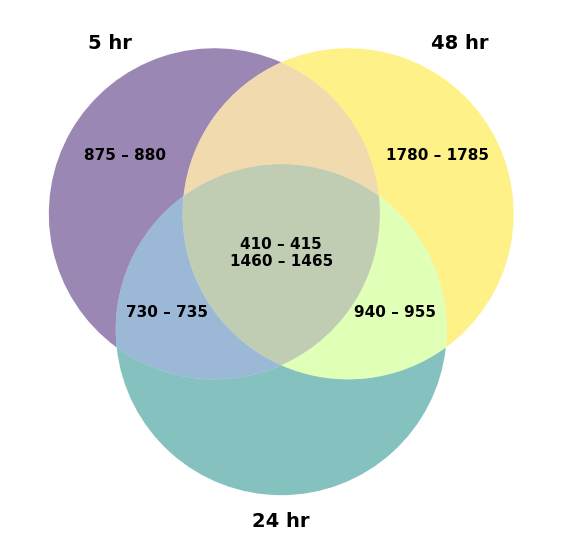

In [14]:
# Fig. 8 - Venn diagram of the consistently influential wavenumber regions of the age classifier for 5, 24 and 48 h.
# The ranges in A / B / C are HARD-CODED (start, end in cm-1) for the 5 h, 24 h and 48 h classes respectively, i.e. they are not computed in this cell;
# update them if the models or thresholds change. Overlapping regions appear in the overlaps of the circles.
# Note that venn3 is given the labels in the order (5 hr, 48 hr, 24 hr), so set C (48 h) is placed in the second circle and set B (24 h) in the third.
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib_venn import venn3_unweighted

# -------------------------------
# Global style parameters
# -------------------------------
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

# -------------------------------
# Input ranges
# -------------------------------
# Wavenumber regions (start / end, cm-1) flagged in at least two folds for each class: A = 5 h, B = 24 h, C = 48 h
A_start = [410, 730, 875, 1460]
A_end   = [415, 735, 880, 1465]

B_start = [410, 730, 940, 1460]
B_end   = [415, 735, 955, 1465]

C_start = [410, 940, 1460, 1780]
C_end   = [415, 955, 1465, 1785]

# -------------------------------
# Convert ranges to sets of tuples
# -------------------------------
# Treat each region as a (start, end) pair so set operations find shared regions
A = set(zip(A_start, A_end))
B = set(zip(B_start, B_end))
C = set(zip(C_start, C_end))

# -------------------------------
# Compute regions
# -------------------------------
# Regions unique to one class or shared by two / all three classes
A_only = A - B - C
B_only = B - A - C
C_only = C - A - B

A_B   = (A & B) - C
A_C   = (A & C) - B
B_C   = (B & C) - A
A_B_C = A & B & C

# -------------------------------
# Formatting helper: "start – end"
# -------------------------------
def ranges_to_text(ranges):
    if not ranges:
        return ""
    return "\n".join(f"{s} – {e}" for s, e in sorted(ranges))

# -------------------------------
# Colormap setup (semantic: hours)
# -------------------------------
# Use the same viridis colours as in the PCA figures (culture age 0-48 h)
cmap = cm.viridis
norm = plt.Normalize(vmin=0, vmax=48)  # hours

# -------------------------------
# Plot (symmetric layout)
# -------------------------------
plt.figure(figsize=(7, 7))

# Draw an unweighted 3-circle Venn diagram with one circle per age class
v = venn3_unweighted(
    subsets=(1, 1, 1, 1, 1, 1, 1),
    set_labels=("5 hr", "48 hr", "24 hr"),
    set_colors=(cmap(norm(5)), cmap(norm(48)), cmap(norm(24))),
    alpha=0.55,
)

# -------------------------------
# Insert formatted text
# -------------------------------
# Write the wavenumber ranges into each region of the diagram
v.get_label_by_id('100').set_text(ranges_to_text(A_only))
v.get_label_by_id('010').set_text(ranges_to_text(C_only))
v.get_label_by_id('001').set_text(ranges_to_text(B_only))
v.get_label_by_id('110').set_text(ranges_to_text(A_C))
v.get_label_by_id('101').set_text(ranges_to_text(A_B))
v.get_label_by_id('011').set_text(ranges_to_text(B_C))
v.get_label_by_id('111').set_text(ranges_to_text(A_B_C))

# -------------------------------
# Text styling
# -------------------------------
# Label styling
for text in v.subset_labels:
    if text:
        text.set_fontweight("bold")
        text.set_ha("center")
        text.set_va("center")
        text.set_fontsize(11)

# Emphasize set labels
for label in v.set_labels:
    label.set_fontsize(14)
    label.set_fontweight("bold")

# -------------------------------
# Nudge the B ∩ C label (945 – 955) to the right
# -------------------------------
# Small manual position nudges (the four repeated blocks below) so that neighbouring labels do not overlap
bc_label = v.get_label_by_id('011')  # B ∩ C region

if bc_label:
    x, y = bc_label.get_position()
    bc_label.set_position((x + 0.03, y))  # adjust 0.08 if needed

# # -------------------------------
# # Nudge the B ∩ C label (945 – 955) to the right
# # -------------------------------
bc_label = v.get_label_by_id('101')  # B ∩ C region

if bc_label:
    x, y = bc_label.get_position()
    bc_label.set_position((x - 0.03, y))  # adjust 0.08 if needed
    

# -------------------------------
# Nudge the B ∩ C label (945 – 955) to the right
# -------------------------------
bc_label = v.get_label_by_id('100')  # B ∩ C region

if bc_label:
    x, y = bc_label.get_position()
    bc_label.set_position((x + 0.03, y))  # adjust 0.08 if needed

# # -------------------------------
# # Nudge the B ∩ C label (945 – 955) to the right
# # -------------------------------
bc_label = v.get_label_by_id('010')  # B ∩ C region

if bc_label:
    x, y = bc_label.get_position()
    bc_label.set_position((x - 0.03, y))  # adjust 0.08 if needed


plt.savefig("Paper and SI images\\Figure_8.svg", dpi = 400)
plt.show()